In [2]:
pip install dash 


   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/7.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/7.2 MB 1.9 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/7.2 MB 2.7 MB/s eta 0:00:03
   ---------- ----------------------------- 1.8/7.2 MB 2.4 MB/s eta 0:00:03
   ----------------------- ---------------- 4.2/7.2 MB 4.5 MB/s eta 0:00:01
   --------------------------------- ------ 6.0/7.2 MB 5.4 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 5.8 MB/s  0:00:01

   -------------------- ------------------- 1/2 [dash]
   -------------------- ------------------- 1/2 [dash]
   -------------------- ------------------- 1/2 [dash]
   -------------------- ------------------- 1/2 [dash]
   -------------------- ------------------- 1/2 [dash]
   -------------------- ------------------- 1/2 [dash]
   ------

In [3]:
pip install pandas


Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install dash_ag_grid


Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install dash --upgrade

Note: you may need to restart the kernel to use updated packages.


In [6]:
pip install "dash[cloud]"

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression


In [2]:
df = pd.read_excel('DataSet.xlsx')

In [3]:
display(df.head())
display(df.info())

,Column1,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,...,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes
0,58,Male,Asian,Highschool,Lower-Middle,Employed,Never,0,215,5.7,...,41,160,145,136,236,6.36,8.18,29.6,Type 2,1
1,52,Female,White,Highschool,Middle,Employed,Former,1,143,6.7,...,55,50,30,93,150,2.00,5.63,23.0,No Diabetes,0
2,60,Male,Hispanic,Highschool,Middle,Unemployed,Never,1,57,6.4,...,66,99,36,118,195,5.07,7.51,44.7,Type 2,1
3,74,Female,Black,Highschool,Low,Retired,Never,0,49,3.4,...,50,79,140,139,253,5.28,9.03,38.2,Type 2,1
4,46,Male,White,Graduate,Middle,Retired,Never,1,109,7.2,...,52,125,160,137,184,12.74,7.20,23.5,Type 2,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97297 entries, 0 to 97296
Data columns (total 31 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Column1                             97297 non-null  int64  
 1   gender                              97297 non-null  object 
 2   ethnicity                           97297 non-null  object 
 3   education_level                     97297 non-null  object 
 4   income_level                        97297 non-null  object 
 5   employment_status                   97297 non-null  object 
 6   smoking_status                      97297 non-null  object 
 7   alcohol_consumption_per_week        97297 non-null  int64  
 8   physical_activity_minutes_per_week  97297 non-null  int64  
 9   diet_score                          97297 non-null  float64
 10  sleep_hours_per_day                 97297 non-null  float64
 11  screen_time_hours_per_day           97297

None

In [7]:
features = df.columns.tolist()
print(features)


['Column1', 'gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c', 'diabetes_risk_score', 'diabetes_stage', 'diagnosed_diabetes']


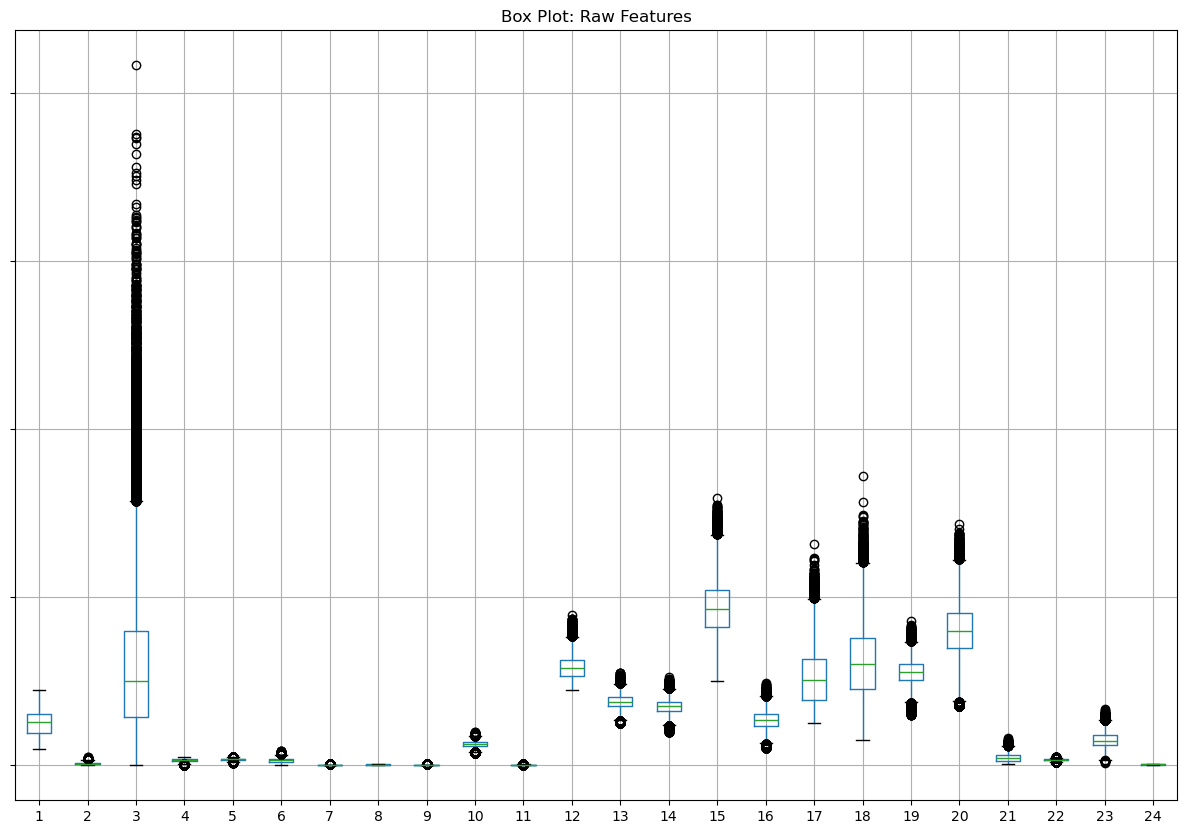

In [8]:
fig, ax = plt.subplots(figsize=(15, 10))
boxplot = df[features].boxplot(vert = 0, ax=ax)  
_ = ax.set_title(f'Box Plot: Raw Features')


In [9]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Column1,97297.0,50.192699,15.492557,19.00,38.00,51.00,61.00,90.00
alcohol_consumption_per_week,97297.0,2.004543,1.418060,0.00,1.00,2.00,3.00,10.00
physical_activity_minutes_per_week,97297.0,118.942886,84.441920,0.00,57.00,100.00,160.00,833.00
diet_score,97297.0,5.995214,1.780096,0.00,4.80,6.00,7.20,10.00
sleep_hours_per_day,97297.0,6.997708,1.093726,3.00,6.30,7.00,7.70,10.00
screen_time_hours_per_day,97297.0,5.997031,2.469805,0.50,4.30,6.00,7.70,16.80
family_history_diabetes,97297.0,0.219657,0.414017,0.00,0.00,0.00,0.00,1.00
hypertension_history,97297.0,0.250912,0.433540,0.00,0.00,0.00,1.00,1.00
cardiovascular_history,97297.0,0.079067,0.269845,0.00,0.00,0.00,0.00,1.00
bmi,97297.0,25.615093,3.588387,15.00,23.20,25.60,28.00,39.20


In [10]:
duplicates = df[df.duplicated()]
print(duplicates)


Empty DataFrame
Columns: [Column1, gender, ethnicity, education_level, income_level, employment_status, smoking_status, alcohol_consumption_per_week, physical_activity_minutes_per_week, diet_score, sleep_hours_per_day, screen_time_hours_per_day, family_history_diabetes, hypertension_history, cardiovascular_history, bmi, waist_to_hip_ratio, systolic_bp, diastolic_bp, heart_rate, cholesterol_total, hdl_cholesterol, ldl_cholesterol, triglycerides, glucose_fasting, glucose_postprandial, insulin_level, hba1c, diabetes_risk_score, diabetes_stage, diagnosed_diabetes]
Index: []

[0 rows x 31 columns]


In [12]:
import dash
from dash import html, dcc, Input, Output, State
import numpy as np

# Initialize app
app = dash.Dash()
app.title = "Diabetes Risk Predictor"

# Layout (UI)
app.layout = html.Div([
    
    html.H1("Diabetes Risk Prediction Dashboard", style={"textAlign": "center"}),

    html.Div([
        html.Label("Glucose Level"),
        dcc.Input(id="glucose", type="number", placeholder="Enter glucose value"),

        html.Br(), html.Br(),

        html.Label("BMI"),
        dcc.Input(id="bmi", type="number", placeholder="Enter BMI"),

        html.Br(), html.Br(),

        html.Label("Age"),
        dcc.Input(id="age", type="number", placeholder="Enter age"),

        html.Br(), html.Br(),

        html.Button("Predict", id="predict-btn", n_clicks=0),

        html.Br(), html.Br(),

        html.H3(id="output-result")

    ], style={"width": "50%", "margin": "auto"})
])


# Simple prediction function (REPLACE with your ML model later)
def simple_model(glucose, bmi, age):
    score = 0.02 * glucose + 0.5 * bmi + 0.03 * age - 5
    return "High Risk" if score > 0 else "Low Risk"


# Callback (core logic)
@app.callback(
    Output("output-result", "children"),
    Input("predict-btn", "n_clicks"),
    State("glucose", "value"),
    State("bmi", "value"),
    State("age", "value"),
)
def predict(n_clicks, glucose, bmi, age):
    if n_clicks == 0:
        return ""

    # Handle missing inputs
    if glucose is None or bmi is None or age is None:
        return "⚠️ Please fill in all fields"

    # Run prediction
    result = simple_model(glucose, bmi, age)

    return f"Prediction: {result}"


# Run server
if __name__ == "__main__":
    app.run(debug=True)